# Privacy-Preserving Diabetes Prediction with Federated Learning
**MSc Computing dissertation notebook – Nikhil Reddy Meesala (C5057483), Sheffield Hallam University**

This notebook walks through the whole experiment on the Pima Indians Diabetes Database:
data overview → preprocessing → centralised baselines → federated learning (FedAvg / FedProx,
3 and 5 clients, IID and non-IID) → results comparison → effect of DP-style noise.

All code lives in `src/`; the notebook calls it so the numbers match `run_experiments.py` exactly.

## 1. Setup

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, yaml
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data_prep import load_pima, prepare_data, FEATURES, ZERO_AS_MISSING
from src.centralised import train_logistic_regression, train_random_forest, train_pooled_sgd, predict_proba
from src.federated import run_federated, partition_iid, partition_label_skew
from src.metrics import compute_metrics, METRIC_KEYS

cfg = yaml.safe_load((ROOT / "config.yaml").read_text())
SEED = cfg["seed"]
pd.set_option("display.precision", 3)
print("seed =", SEED, "| rounds =", cfg["federated"]["rounds"], "| local epochs =", cfg["federated"]["local_epochs"])

seed = 42 | rounds = 15 | local epochs = 5


## 2. Data overview
The dataset has 768 rows, 8 clinical features and a binary `Outcome` (1 = diabetes).

In [2]:
df = load_pima(ROOT / cfg["data"]["csv_path"])
print("shape:", df.shape)
print("class counts:", df["Outcome"].value_counts().to_dict())
df.head()

shape: (768, 9)
class counts: {0: 500, 1: 268}


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
zero_counts = (df[FEATURES] == 0).sum().rename("rows with value 0")
summary = df.describe().T[["mean", "std", "min", "max"]].join(zero_counts)
summary

,mean,std,min,max,rows with value 0
Pregnancies,3.845,3.370,0.000,17.00,111.0
Glucose,120.895,31.973,0.000,199.00,5.0
BloodPressure,69.105,19.356,0.000,122.00,35.0
SkinThickness,20.536,15.952,0.000,99.00,227.0
Insulin,79.799,115.244,0.000,846.00,374.0
BMI,31.993,7.884,0.000,67.10,11.0
DiabetesPedigreeFunction,0.472,0.331,0.078,2.42,0.0
Age,33.241,11.760,21.000,81.00,0.0
Outcome,0.349,0.477,0.000,1.00,NaN


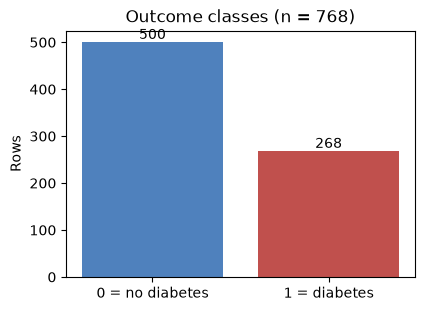

In [4]:
counts = df["Outcome"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(4.5, 3.2))
bars = ax.bar(["0 = no diabetes", "1 = diabetes"], counts, color=["#4f81bd", "#c0504d"])
ax.bar_label(bars); ax.set_ylabel("Rows"); ax.set_title("Outcome classes (n = 768)")
plt.show()

## 3. Preprocessing
* stratified 80/20 split with `random_state = 42` → 614 train / 154 test rows
* zeros in Glucose, BloodPressure, SkinThickness, Insulin and BMI are impossible values, so they
  are treated as missing and filled with the **training-set median**
* `StandardScaler` is **fitted on training rows only**, then applied to the test rows

In [5]:
data = prepare_data(df, cfg["data"]["test_size"], SEED, cfg["data"]["zero_as_missing"])
Xtr, Xte, ytr, yte = data.X_train, data.X_test, data.y_train, data.y_test
print(f"train = {len(ytr)} rows ({ytr.mean():.1%} diabetes) | test = {len(yte)} rows ({yte.mean():.1%} diabetes)")
print("training medians used for imputation:", {k: round(v, 1) for k, v in data.imputer.medians_.items()})
print("scaled train mean ≈", np.round(Xtr.mean(axis=0), 3))

train = 614 rows (34.9% diabetes) | test = 154 rows (35.1% diabetes)
training medians used for imputation: {'Glucose': 117.0, 'BloodPressure': 72.0, 'SkinThickness': 29.0, 'Insulin': 125.0, 'BMI': 32.4}
scaled train mean ≈ [-0. -0.  0. -0. -0.  0. -0. -0.]


## 4. Centralised baselines
All 614 training rows in one place. Logistic regression is the main baseline; random forest is a stronger non-linear reference; SGD-LR is the exact federated client optimiser run on pooled data.

In [6]:
rows, probs = [], {}
def evaluate(label, prob):
    m = compute_metrics(yte, prob); probs[label] = prob
    rows.append({"Model": label, **{k: m[k] for k in METRIC_KEYS}}); return m

c, f = cfg["centralised"], cfg["federated"]
lr = train_logistic_regression(Xtr, ytr, SEED, **c["logistic_regression"])
rf = train_random_forest(Xtr, ytr, SEED, **c["random_forest"])
sgd = train_pooled_sgd(Xtr, ytr, epochs=c["sgd_logreg"]["epochs"], lr=f["learning_rate"],
                       batch_size=f["batch_size"], l2=f["l2"], class_weight=f["class_weight"], seed=SEED)
m_lr = evaluate("Central LR", lr.predict_proba(Xte)[:, 1])
evaluate("Central RF", rf.predict_proba(Xte)[:, 1])
evaluate("Central SGD-LR", predict_proba(sgd, Xte))
pd.DataFrame(rows).set_index("Model")

,accuracy,precision,recall,f1,roc_auc
Model,,,,,
Central LR,0.734,0.603,0.704,0.650,0.813
Central RF,0.747,0.623,0.704,0.661,0.831
Central SGD-LR,0.734,0.603,0.704,0.650,0.812


## 5. Federated clients: IID vs non-IID shards
IID shards keep the same label mix on every client. Non-IID shards use Dirichlet label skew (α = 0.5), so some clients hold mostly diabetes cases and others mostly non-diabetes cases. Shards are disjoint: no row is on two clients.

In [7]:
a = cfg["federated"]["non_iid"]["alpha"]
shards = {"5 clients IID": partition_iid(ytr, 5, np.random.default_rng(SEED)),
          "5 clients non-IID": partition_label_skew(ytr, 5, np.random.default_rng(SEED), a, 20)}
table = pd.DataFrame({name: [f"{len(s)} rows, {ytr[s].mean():.0%} diabetes" for s in sh]
                      for name, sh in shards.items()}, index=[f"Client {i+1}" for i in range(5)])
table

,5 clients IID,5 clients non-IID
Client 1,"123 rows, 35% diabetes","27 rows, 96% diabetes"
Client 2,"123 rows, 35% diabetes","37 rows, 16% diabetes"
Client 3,"123 rows, 35% diabetes","119 rows, 92% diabetes"
Client 4,"123 rows, 35% diabetes","110 rows, 55% diabetes"
Client 5,"122 rows, 34% diabetes","321 rows, 4% diabetes"


## 6. Federated training (15 rounds)
Each round: the server sends the global model → every client runs **E = 5 epochs of local
mini-batch SGD** on its own rows → clients send back only their parameter update → the server
takes a **weighted average (FedAvg)**. FedProx adds a proximal term μ/2·‖w − w_global‖² to each
client's loss (μ = 0.1).

In [8]:
kw = dict(rounds=f["rounds"], local_epochs=f["local_epochs"], lr=f["learning_rate"],
          batch_size=f["batch_size"], l2=f["l2"], class_weight=f["class_weight"],
          alpha=f["non_iid"]["alpha"], min_client_size=f["non_iid"]["min_client_size"], seed=SEED)
histories = {}
for k in f["client_counts"]:
    for part in ("iid", "non_iid"):
        for strat in ("fedavg", "fedprox"):
            label = f"FL{k} {'IID' if part=='iid' else 'non-IID'} {'FedAvg' if strat=='fedavg' else 'FedProx'}"
            r = run_federated(Xtr, ytr, Xte, yte, n_clients=k, partition=part, strategy=strat,
                              mu=f["fedprox_mu"], **kw)
            evaluate(label, predict_proba(r.params, Xte)); histories[label] = r.history
print(f"trained {len(histories)} federated configurations")

trained 8 federated configurations


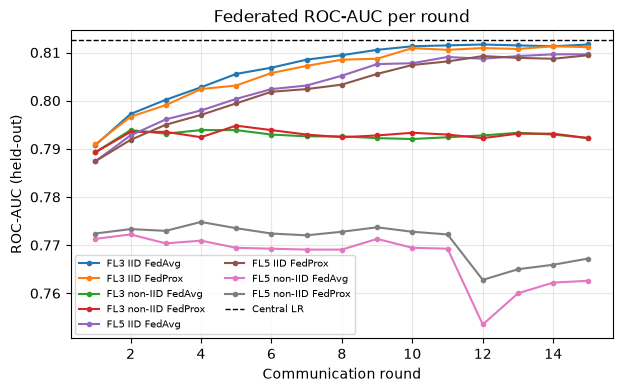

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
for label, h in histories.items():
    ax.plot([x["round"] for x in h], [x["roc_auc"] for x in h], marker="o", ms=3, label=label)
ax.axhline(m_lr["roc_auc"], color="k", ls="--", lw=1, label="Central LR")
ax.set_xlabel("Communication round"); ax.set_ylabel("ROC-AUC (held-out)")
ax.set_title("Federated ROC-AUC per round"); ax.legend(fontsize=7, ncol=2); ax.grid(alpha=.3)
plt.show()

## 7. Results comparison (held-out test set, n = 154)

In [10]:
results = pd.DataFrame(rows).set_index("Model")
results["AUC gap vs Central LR"] = results["roc_auc"] - m_lr["roc_auc"]
results.round(3)

,accuracy,precision,recall,f1,roc_auc,AUC gap vs Central LR
Model,,,,,,
Central LR,0.734,0.603,0.704,0.650,0.813,0.000
Central RF,0.747,0.623,0.704,0.661,0.831,0.018
Central SGD-LR,0.734,0.603,0.704,0.650,0.812,-0.000
FL3 IID FedAvg,0.727,0.597,0.685,0.638,0.812,-0.001
FL3 IID FedProx,0.727,0.597,0.685,0.638,0.811,-0.001
FL3 non-IID FedAvg,0.695,0.552,0.685,0.612,0.792,-0.020
FL3 non-IID FedProx,0.695,0.552,0.685,0.612,0.792,-0.020
FL5 IID FedAvg,0.714,0.578,0.685,0.627,0.810,-0.003
FL5 IID FedProx,0.708,0.571,0.667,0.615,0.809,-0.003


## 8. Effect of DP-style clipping + Gaussian noise
Each client clips its update to L2 norm C = 1.0 and adds noise N(0, (σ·C)²) before sending. No formal (ε, δ) accounting is done, so this shows the utility cost of noise rather than a privacy guarantee.

,accuracy,precision,recall,f1,roc_auc
noise σ,,,,,
0.00,0.714,0.578,0.685,0.627,0.810
0.10,0.740,0.606,0.741,0.667,0.810
0.25,0.727,0.591,0.722,0.650,0.804
0.50,0.727,0.583,0.778,0.667,0.782
1.00,0.675,0.525,0.778,0.627,0.744
2.00,0.630,0.483,0.778,0.596,0.712


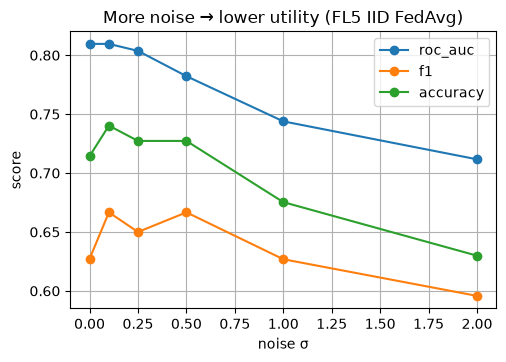

In [11]:
dp = cfg["federated"]["dp"]; sweep = []
for sigma in dp["sweep"]:
    r = run_federated(Xtr, ytr, Xte, yte, n_clients=5, partition="iid", strategy="fedavg",
                      dp_clip=dp["clip_norm"], dp_noise=sigma, **kw)
    m = compute_metrics(yte, predict_proba(r.params, Xte))
    sweep.append({"noise σ": sigma, **{k: m[k] for k in METRIC_KEYS}})
sweep = pd.DataFrame(sweep).set_index("noise σ")
display(sweep.round(3))
ax = sweep[["roc_auc", "f1", "accuracy"]].plot(marker="o", figsize=(5.5, 3.6), grid=True)
ax.set_ylabel("score"); ax.set_title("More noise → lower utility (FL5 IID FedAvg)"); plt.show()

## 9. ROC curves, confusion matrices and feature importances
The curves and matrices below use the same held-out test set (n = 154) and the probabilities stored in `probs` above. The noise run uses the headline setting from `config.yaml` (clip norm C = 1.0, noise multiplier σ = 0.5).

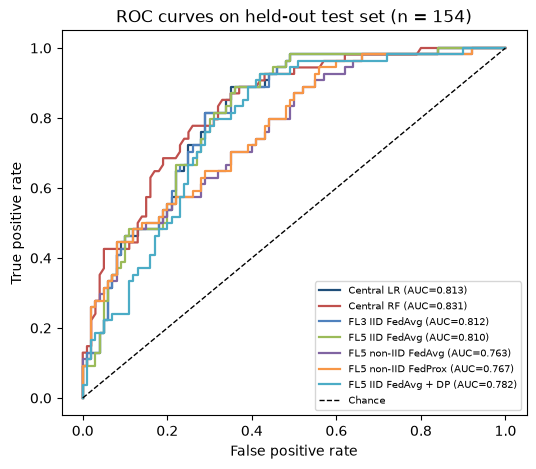

In [12]:
from sklearn.metrics import roc_curve
PALETTE = ["#1f4e79", "#c0504d", "#4f81bd", "#9bbb59", "#8064a2", "#f79646", "#4bacc6"]
r_dp = run_federated(Xtr, ytr, Xte, yte, n_clients=5, partition="iid", strategy="fedavg",
                     dp_clip=dp["clip_norm"], dp_noise=dp["noise_multiplier"], **kw)
probs["FL5 IID FedAvg + DP"] = predict_proba(r_dp.params, Xte)
roc_models = ["Central LR", "Central RF", "FL3 IID FedAvg", "FL5 IID FedAvg",
              "FL5 non-IID FedAvg", "FL5 non-IID FedProx", "FL5 IID FedAvg + DP"]
fig, ax = plt.subplots(figsize=(6, 5))
for k, label in enumerate(roc_models):
    fpr, tpr, _ = roc_curve(yte, probs[label])
    auc = compute_metrics(yte, probs[label])["roc_auc"]
    ax.plot(fpr, tpr, color=PALETTE[k], lw=1.6, label=f"{label} (AUC={auc:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title(f"ROC curves on held-out test set (n = {len(yte)})"); ax.legend(fontsize=7.5, loc="lower right")
plt.show()

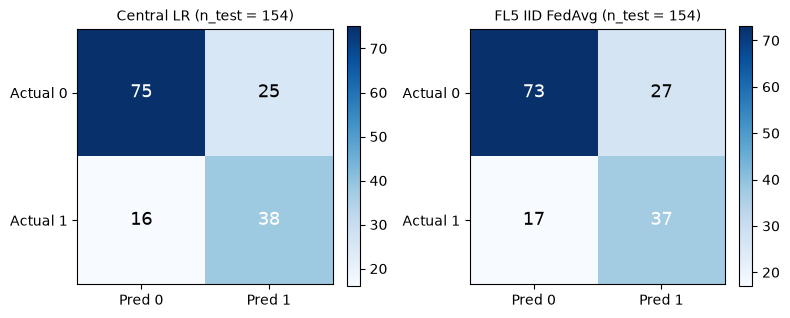

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.4))
for ax, label in zip(axes, ["Central LR", "FL5 IID FedAvg"]):
    cm = compute_metrics(yte, probs[label])["confusion_matrix"]
    mat = np.array([[cm["tn"], cm["fp"]], [cm["fn"], cm["tp"]]])
    im = ax.imshow(mat, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, mat[i, j], ha="center", va="center", fontsize=13,
                    color="white" if mat[i, j] > mat.max() / 2 else "black")
    ax.set_xticks([0, 1], ["Pred 0", "Pred 1"]); ax.set_yticks([0, 1], ["Actual 0", "Actual 1"])
    ax.set_title(f"{label} (n_test = {len(yte)})", fontsize=10); fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

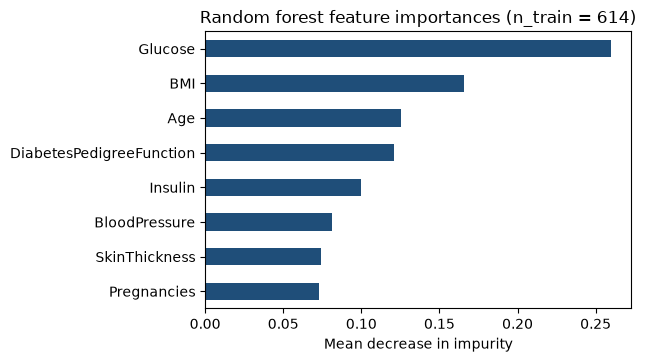

{'Glucose': 0.26, 'BMI': 0.166, 'Age': 0.125, 'DiabetesPedigreeFunction': 0.121, 'Insulin': 0.1, 'BloodPressure': 0.081, 'SkinThickness': 0.074, 'Pregnancies': 0.073}


In [14]:
imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
ax = imp.plot.barh(color="#1f4e79", figsize=(5.5, 3.6))
ax.set_xlabel("Mean decrease in impurity")
ax.set_title(f"Random forest feature importances (n_train = {len(ytr)})"); plt.show()
print(imp.sort_values(ascending=False).round(3).to_dict())

## 10. Cross-checks
**(a)** the notebook numbers equal the exported `results/metrics.json`; **(b)** a Flower (flwr) simulation of the same settings gives very similar results.

In [15]:
exported = {r["label"]: r for r in json.loads((ROOT / "results/metrics.json").read_text())["runs"]}
diff = max(abs(exported[m][k] - results.loc[m, k]) for m in results.index for k in METRIC_KEYS)
print(f"largest difference vs results/metrics.json: {diff:.2e}")
fl = ROOT / "results/flower_crosscheck.json"
if fl.exists():
    for name, v in json.loads(fl.read_text()).items():
        print(name, {k: round(v["final"][k], 3) for k in METRIC_KEYS})

largest difference vs results/metrics.json: 0.00e+00
flower_fl5_iid_fedavg {'accuracy': 0.714, 'precision': 0.578, 'recall': 0.685, 'f1': 0.627, 'roc_auc': 0.81}
flower_fl5_non_iid_fedprox {'accuracy': 0.675, 'precision': 0.531, 'recall': 0.63, 'f1': 0.576, 'roc_auc': 0.771}


## 11. Summary
* Federated training reaches ROC-AUC close to the centralised logistic regression when client
  data are IID, without any raw row leaving its client.
* Strong label skew (non-IID) lowers performance; FedProx gives at most a small change here.
* Adding DP-style noise trades ROC-AUC for protection of individual updates.
* This is a demonstration on one small public dataset, **not** a clinical tool.